# 02 Sections computation

This notebook assumes that you have got a pre-processed mesh and centreline ready to go. If this is not the case, you can run the previous steps in notebook ``01_MeshPreprocessing.iynb``

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from stl import mesh
from os.path import exists, split, join
from os import makedirs
from tqdm import tqdm

from base.iterative_section_minimiser import mesh_intersect
from base.utils import list_all_plymeshes, return_centreline_parametrisation


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


We list all possible meshes in the repository and then run a few assertions on pre-compiled files.

In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 
passages_filepaths = list_all_plymeshes(data_repository)

In [ ]:
idx = 5
plymesh = passages_filepaths[idx]
stlmesh = plymesh[:-4] +".stl"
assert exists(stlmesh)
mesh_data = mesh.Mesh.from_file(stlmesh)

In [4]:
adjacent_triangles_filepath = stlmesh[:-4]+ "_adjacent_triangles.txt"
assert exists(adjacent_triangles_filepath)
adjacent_triangles = np.loadtxt(adjacent_triangles_filepath).astype(int)

In [5]:
# here's a quick test to show that the adjacency matrix file is probably fine.
assert len(adjacent_triangles) == len(mesh_data.vectors)

In [6]:
centreline_filepath = join(split(stlmesh)[0][:-4], "geometric_descriptors", split(stlmesh)[1][:-12] + "centreline.txt")
assert exists(centreline_filepath)
centreline = np.loadtxt(centreline_filepath, skiprows=1)

If all those tests have passed, this means we have a mesh loaded in memory, an adjacency matrix, and a centreline. We should now be able to compute some a-priori vector directions. 

In [7]:
# at each point in the centreline, use its two neighbours to estimate the passage direction. 
curvilinear_coords, normed_vectors = return_centreline_parametrisation(centreline)

Now we check whether the directory for storing section files is there or not. 

In [8]:
sections_directory = join(split(stlmesh)[0][:-4], "geometric_descriptors", "sections")
if exists(sections_directory):
    print("sections_directory already exists")
else:
    makedirs(sections_directory)

sections_directory already exists


In [9]:
keep_sections = True

# we iterated over every point of the centreline. 
for c, (P, nP) in tqdm(enumerate(zip(centreline[1:-1], normed_vectors)), total=len(normed_vectors)):
    
    section_filepath = join(sections_directory, f"s{c}.txt")
    
    if exists(section_filepath) and keep_sections:
        thesection = np.loadtxt(section_filepath, skiprows=1)
    else:
        thesection = mesh_intersect(mesh_data, P, nP)[0]
        np.savetxt(section_filepath, thesection, header="X, Y, Z")

#sections = [mesh_intersect(mesh_data, P, nP) for P, nP in tqdm(zip(centreline[1:-1], normed_vectors), total=len(normed_vectors))]

100%|███████████████████████████████████████████████████████████████████████████████| 443/443 [00:00<00:00, 603.60it/s]


Sanity check by reading out the written sections and plotting them against the mesh data. 

In [10]:
sections = [np.loadtxt(join(sections_directory, f"s{c}.txt"), skiprows=1) for c in range(len(normed_vectors))]

Text(0.5, 0, 'X [m]')

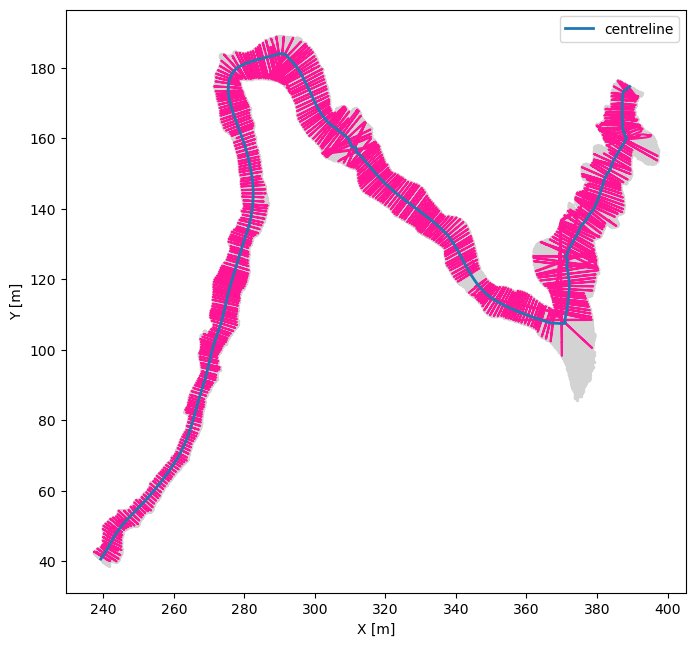

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")

for section in sections:
    if section is not None:
        ax.plot(*section[:, [0,1]].T, color = "deeppink")

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")